# A8 — Cybersecurity: Spotting Attacks as 'Odd One Out'

Vivekananda GN

learn what *normal* network traffic looks like and flag anything unusual (attacks) without ever seeing attack examples. This is **anomaly detection**.
We compare a quantum-kernel One-Class SVM with a classical one on **synthetic** traffic (4 features: packets/second, average packet size, connection duration, distinct ports).

In [ ]:
# Run once (Google Colab or local). Qibo = open-source quantum simulator (qibo.science)
!pip install -q qibo scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.5/369.5 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 11.1 MB/s eta 0:00:00


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qibo import Circuit, gates, set_backend
set_backend("numpy")
np.set_printoptions(precision=3, suppress=True)
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, roc_curve

[Qibo 0.3.5|INFO|2026-10-03 06:18:08]: Using numpy backend on /CPU:0
INFO:qibo.config:Using numpy backend on /CPU:0


In [ ]:
def feature_state(x, n=4, scale=1.0, reps=2):
    c = Circuit(n)
    for _ in range(reps):
        for q in range(n):
            c.add(gates.H(q)); c.add(gates.RY(q, scale * x[q]))
        for q in range(n - 1): c.add(gates.CNOT(q, q + 1))
        for q in range(n): c.add(gates.RZ(q, scale * x[q]))
        for q in range(n - 1): c.add(gates.CNOT(q, q + 1))
    return np.array(c().state())

def quantum_kernel(A, B, **kw):
    SA = np.array([feature_state(a, **kw) for a in A]); SB = np.array([feature_state(b, **kw) for b in B])
    return np.abs(SA.conj() @ SB.T) ** 2          # similarity of two quantum states (1 = identical)

## 1. Synthetic traffic: normal behaviour + three kinds of attack

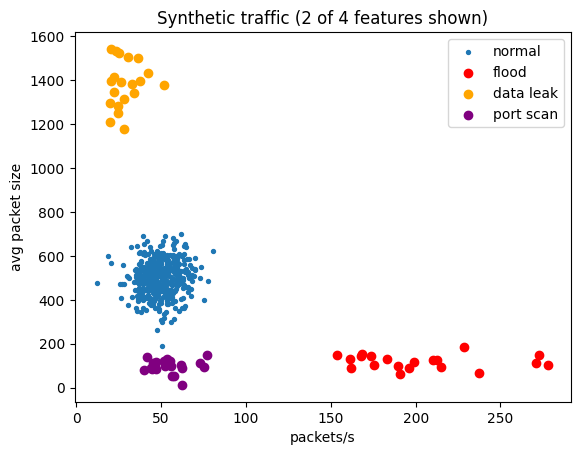

In [ ]:
rng = np.random.default_rng(0)
normal = np.column_stack([rng.normal(50, 10, 400), rng.normal(500, 80, 400), rng.normal(30, 8, 400), rng.normal(5, 1.5, 400)])
flood = np.column_stack([rng.normal(200, 30, 20), rng.normal(120, 30, 20), rng.normal(5, 2, 20), rng.normal(3, 1, 20)])        # DDoS-like flood
scan  = np.column_stack([rng.normal(60, 10, 20), rng.normal(100, 30, 20), rng.normal(2, 1, 20), rng.normal(40, 8, 20)])         # port scan
leak  = np.column_stack([rng.normal(30, 8, 20), rng.normal(1400, 100, 20), rng.normal(120, 20, 20), rng.normal(4, 1, 20)])       # data exfiltration
names = ['packets/s', 'avg size', 'duration', 'ports']
plt.scatter(normal[:, 0], normal[:, 1], s=8, label='normal'); plt.scatter(flood[:, 0], flood[:, 1], label='flood', c='r')
plt.scatter(leak[:, 0], leak[:, 1], label='data leak', c='orange'); plt.scatter(scan[:, 0], scan[:, 1], label='port scan', c='purple')
plt.xlabel('packets/s'); plt.ylabel('avg packet size'); plt.legend(); plt.title('Synthetic traffic (2 of 4 features shown)'); plt.show()

## 2. Train on normal traffic only; test on a mix of normal and attacks

In [ ]:
train = normal[:200]; test = np.vstack([normal[200:], flood, scan, leak]); truth = np.r_[np.zeros(200), np.ones(60)]   # 1 = attack
sc = MinMaxScaler((0, np.pi)).fit(train); f = lambda Z: np.clip(sc.transform(Z), -0.5, np.pi + 0.5)
A, B = f(train), f(test)
res = {}
for s in [0.25, 0.5, 1.0]:
    ocq = OneClassSVM(kernel='precomputed', nu=0.05).fit(quantum_kernel(A, A, scale=s))
    res[f'quantum kernel (scale {s})'] = roc_auc_score(truth, -ocq.decision_function(quantum_kernel(B, A, scale=s)))
for g in [0.05, 0.2, 1.0]:
    occ = OneClassSVM(gamma=g, nu=0.05).fit(A); res[f'classical RBF (gamma {g})'] = roc_auc_score(truth, -occ.decision_function(B))
for k, v in res.items(): print(f"{k:<30} detection quality (AUC, 1.0 = perfect): {v:.3f}")

quantum kernel (scale 0.25)    detection quality (AUC, 1.0 = perfect): 1.000
quantum kernel (scale 0.5)     detection quality (AUC, 1.0 = perfect): 0.992
quantum kernel (scale 1.0)     detection quality (AUC, 1.0 = perfect): 0.967
classical RBF (gamma 0.05)     detection quality (AUC, 1.0 = perfect): 1.000
classical RBF (gamma 0.2)      detection quality (AUC, 1.0 = perfect): 1.000
classical RBF (gamma 1.0)      detection quality (AUC, 1.0 = perfect): 1.000


## 3. Which attacks does it catch?

In [ ]:
s = 0.5
ocq = OneClassSVM(kernel='precomputed', nu=0.05).fit(quantum_kernel(A, A, scale=s))
flag = ocq.predict(quantum_kernel(B, A, scale=s)) == -1
groups = {'normal (false alarms)': slice(0, 200), 'flood': slice(200, 220), 'port scan': slice(220, 240), 'data leak': slice(240, 260)}
for g, sl in groups.items(): print(f"{g:<22} flagged: {flag[sl].mean():.0%}")

normal (false alarms)  flagged: 9%
flood                  flagged: 100%
port scan              flagged: 100%
data leak              flagged: 100%


## 4. a subtle attack
Our three attacks were obvious. Real attackers try to blend in. Here are 20 connections that sit only slightly outside normal behaviour. Who notices?

In [ ]:
rng2 = np.random.default_rng(5)
subtle = np.column_stack([rng2.normal(65, 10, 20), rng2.normal(480, 80, 20), rng2.normal(30, 8, 20), rng2.normal(7.5, 1.5, 20)])
Bs = f(subtle)
occ = OneClassSVM(gamma=0.2, nu=0.05).fit(A)
print("subtle attacks caught  quantum:", (ocq.predict(quantum_kernel(Bs, A, scale=0.5)) == -1).mean(),
      "| classical:", (occ.predict(Bs) == -1).mean())

subtle attacks caught  quantum: 0.15 | classical: 0.35


## 5. Discussion
* Notice what the quantum model needed: **no attack examples**. That is realistic for new, unknown attacks.
* Compare quantum vs classical AUC honestly. Real intrusion data is far larger and messier; published quantum studies use small subsets.
* **Try:** change `nu` (expected fraction of outliers), or add a fourth, subtle attack with values close to normal. Which model notices?

**Observation:** both detectors catch the obvious attacks, but on subtle ones the quantum detector misses most of them and the classical detector does better. 'About equal' is true only for easy cases. Always test the hard cases.